# CMIP6 torchcrop runs — changes in the probability of extreme yields

How much more or less often does a season cross a level that was rare in 1985–2014?

* **Events** are set per model and per cell on `historical` 1985–2014, so model bias does not read as
  risk: below the 10th and 5th percentiles, below half of the baseline mean, above the 90th percentile.
  With 30 seasons a 5th percentile sits between the two lowest values, so treat it as indicative.
* **Reference probability** is leave-one-year-out. An in-sample probability is exact by construction,
  while a future one has threshold sampling error, so comparing the two would overstate change.
* **Uncertainty**: 95 % intervals resample whole model-seasons, which keeps spatial correlation. They do
  not cover the small model sample. The model range is shown as well.
* **The events are absolute.** With CO₂ fertilisation in the runs, a rising mean lowers the chance of
  crossing a fixed level even if the bad years are as bad as before. §4 splits the change into mean and
  variability for this reason.


**Reading these numbers**

* **Scope.** Torchcrop only, on calibrated parameters, for 4 models × 5 experiments, one run per
  model-experiment. Differences between experiments of one model include internal variability.
* **Cells.** The 59,304 cells every run simulated, weighted by cropland area. Each forcing has its own
  frame, and all 5,572 dropped cells lie outside the box the frames share.
* **Fixed crop system.** Cultivar, fertiliser and sowing (per-cell median of the MSWX SIMPLACE dates)
  do not change, so nothing here includes adaptation and sowing cannot respond to the forcing.
* **Wind** is an MSWX climatology in every run, so wind carries no scenario signal.
* **`hist-aer` holds CO₂ at 1850 (284 ppm)**; the other experiments follow their own CO₂. A contrast with
  `hist-aer` therefore mixes the climate effect with the CO₂ effect on the crop.
* **`yield_t_ha` excludes heat sterility.** `adjusted_yield_t_ha` = yield × (1 − heat stress). The
  calibration and evaluation use `yield_t_ha`, so it is the primary series here (see 04's sensitivity test).
* **No season 2015.** Historical runs end at harvest 2014, and SSP runs start with sowing in 2015.

## Findings

**As simulated, low-yield risk falls across most of Europe, but that fall depends on the prescribed CO₂ effect. Without it, far-future `ssp370` risk rises instead.**

| Europe, 1-in-10 low yield, risk ratio [model range] | As simulated | `COTB` removed (§10) |
|---|---|---|
| `ssp126` 2071–2100 | 0.72 [0.51, 0.96] | 1.13 [0.87, 1.34] |
| `ssp370` 2021–2050 | 0.51 [0.37, 0.74] | 0.91 [0.77, 1.16] |
| `ssp370` 2071–2100 | 0.42 [0.28, 0.58] | **1.81 [1.52, 2.30]** |
| `hist-aer` 1985–2014 | 4.15 [3.32, 5.11] | 1.18 [0.89, 1.69] |

* **The rescaling is an approximation, not a rerun.** It passes its test only roughly: `hist-aer` returns to a mean of −0.4 %, but its risk ratio of 1.18 has a range spanning 1. Treat the direction under `ssp370` far as the result, and the 1.81 as indicative.
* **Mean or variability:** as simulated, nearly all of the change comes from the shifting mean (Europe `ssp370` far: −7.2 points in total, −7.7 from the mean). Detrended CV falls by 2.4 points in Europe, and more in the Mediterranean (−5.7) and Eastern Europe (−6.1).
* **Where risk rises even as simulated:** the far south. Models agree on a rise on 5 % of cropland under `ssp370` far, against a fall on 84 %. Spain (+1.9 points) and Greece (+1.1) are the only countries with an increase in that scenario.
* **Synchronous shortfalls:** seasons with ≥ 20 % of cropland below its own 1-in-10 level fall from 18 % to 13 % (`ssp126` far) and 0.8 % (`ssp370` far, one season of 120).
* **Continental 1-in-10 season:** −10 % of baseline today, −6 % in `ssp126` far and +15 % in `ssp370` far.
* **Non-maturing seasons** rise under `ssp370` far from 0.05 % to 0.42 % of cropland area-seasons, and from 0.24 % to 1.19 % in the Mediterranean. These use a fixed sowing date and cultivar.
* **Heat sterility** barely alters the result: adding it raises risk ratios by 0.04–0.08 for Europe. The hotspot with a sharp edge in eastern Ukraine under `ssp370` follows a calibration boundary, so do not read it as climate.

## 0. Setup

In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

sys.path.insert(0, str(Path.cwd()))
import scenarios as sc
from cropmodelling4eu.evaluation.plots import save
from cropmodelling4eu.evaluation.style import SEQUENTIAL_CMAP, DIVERGING_CMAP, use_style

logging.basicConfig(level=logging.WARNING, force=True)
PALETTE = use_style("light")
plt.rcParams["figure.dpi"] = 90
FIGURES, TABLES = sc.table_dir("extremes")
cells = sc.load_cells()
y = sc.cube("yield_t_ha")
EXP_COLOURS = {"historical": PALETTE["primary"], "hist-GHG": PALETTE["series_4"], "hist-aer": PALETTE["series_3"],
               "ssp126": PALETTE["series_1"], "ssp370": PALETTE["series_2"]}
MODEL_COLOURS = dict(zip(sc.MODELS, (PALETTE[f"series_{i}"] for i in (1, 2, 3, 5))))
SPAN = lambda s: f"{s[0]}–{s[1]}"

import risk as rk

limits = {e.key: rk.threshold(y, e) for e in rk.EVENTS}
reference = {e.key: rk.loo_probability(y, e) for e in rk.EVENTS}
SCENARIOS = [("historical", sc.EARLY), ("hist-GHG", sc.BASELINE), ("hist-aer", sc.BASELINE), ("ssp126", sc.NEAR), ("ssp126", sc.FAR), ("ssp370", sc.NEAR), ("ssp370", sc.FAR)]
FUTURE = [s for s in SCENARIOS if s[0] in sc.FUTURE]
TAG = lambda e, s: f"{e} {SPAN(s)}"

print(f"{cells.n} cells; outputs in {FIGURES.parent}")

59304 cells; outputs in /data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu/runs/winter_wheat/calibrated/cmip6/analysis/extremes


## 1. Probability in each region

For each event, scenario and region: the cropland-area probability, the risk ratio against the leave-one-year-out reference, the 95 % interval and the model range.

In [2]:
def summarise(event, data=y, limit=None, base=None):
    limit = limits[event.key] if limit is None else limit
    base = reference[event.key] if base is None else base
    ref = sc.regional_mean(base)
    rows = []
    for e, span in SCENARIOS:
        yearly = sc.regional_mean(rk.hits(sc.period(data.sel(experiment=e), span), limit, event))
        for r in yearly.region.values:
            block = yearly.sel(region=r)
            p_models = block.mean("year")
            ratio = p_models / ref.sel(region=r)
            low, high = rk.bootstrap_ci(block.values.ravel())
            p_ref = float(ref.sel(region=r).mean())
            rows.append({"event": event.key, "scenario": TAG(e, span), "region": r, "reference (%)": 100 * p_ref, "probability (%)": 100 * float(p_models.mean()),
                         "CI low (%)": 100 * low, "CI high (%)": 100 * high, "risk ratio": float(p_models.mean()) / p_ref,
                         "RR model min": float(ratio.min()), "RR model max": float(ratio.max())})
    return pd.DataFrame(rows)

summary = pd.concat([summarise(e) for e in rk.EVENTS], ignore_index=True)
summary.to_csv(TABLES / "event_probability_regions.csv", index=False)
for event in rk.EVENTS:
    print(event.label)
    block = summary[(summary["event"] == event.key) & (summary["region"].isin(["Europe", "WCE", "MED", "EEU", "NEU"]))]
    display(block.pivot(index="scenario", columns="region", values="risk ratio").reindex([TAG(*s) for s in SCENARIOS]).round(2))
display(summary[(summary["region"] == "Europe") & (summary["event"] == "p10")].drop(columns=["event", "region"]).round(2))

Low yield: below the baseline 10th percentile (1-in-10)


region,EEU,Europe,MED,NEU,WCE
scenario,,,,,
historical 1951–1980,2.05,2.97,1.86,6.65,3.25
hist-GHG 1985–2014,1.91,1.33,1.01,0.90,1.35
hist-aer 1985–2014,2.68,4.15,2.83,7.83,4.61
ssp126 2021–2050,0.90,0.67,0.71,0.27,0.63
ssp126 2071–2100,1.01,0.72,0.73,0.18,0.66
ssp370 2021–2050,0.68,0.51,0.55,0.24,0.45
ssp370 2071–2100,0.33,0.42,0.69,0.02,0.30


Very low yield: below the baseline 5th percentile (1-in-20)


region,EEU,Europe,MED,NEU,WCE
scenario,,,,,
historical 1951–1980,2.28,3.46,1.98,9.46,3.73
hist-GHG 1985–2014,2.02,1.41,1.03,1.07,1.42
hist-aer 1985–2014,3.00,5.35,3.39,12.43,5.93
ssp126 2021–2050,0.91,0.68,0.73,0.33,0.62
ssp126 2071–2100,1.00,0.71,0.76,0.19,0.63
ssp370 2021–2050,0.56,0.47,0.54,0.31,0.40
ssp370 2071–2100,0.32,0.49,0.87,0.01,0.32


Failure: below 50 % of the baseline mean


region,EEU,Europe,MED,NEU,WCE
scenario,,,,,
historical 1951–1980,2.19,1.53,1.21,5.78,1.57
hist-GHG 1985–2014,2.13,1.31,0.83,6.15,1.51
hist-aer 1985–2014,2.72,2.14,1.64,33.67,2.39
ssp126 2021–2050,1.00,0.75,0.66,2.70,0.71
ssp126 2071–2100,1.06,0.83,0.68,0.54,0.86
ssp370 2021–2050,0.70,0.65,0.64,2.26,0.59
ssp370 2071–2100,0.37,0.63,0.70,0.01,0.46


High yield: above the baseline 90th percentile


region,EEU,Europe,MED,NEU,WCE
scenario,,,,,
historical 1951–1980,0.08,0.11,0.35,0.00,0.04
hist-GHG 1985–2014,0.50,1.06,1.16,1.29,1.14
hist-aer 1985–2014,0.02,0.05,0.15,0.00,0.02
ssp126 2021–2050,1.13,2.52,2.01,5.51,2.80
ssp126 2071–2100,1.37,2.74,2.01,5.95,3.08
ssp370 2021–2050,1.63,3.02,2.39,6.12,3.38
ssp370 2071–2100,3.57,4.85,3.47,7.80,5.46


,scenario,reference (%),probability (%),CI low (%),CI high (%),risk ratio,RR model min,RR model max
0,historical 1951–1980,12.42,36.94,34.73,39.16,2.97,2.48,3.46
6,hist-GHG 1985–2014,12.42,16.56,14.39,18.77,1.33,1.08,1.51
12,hist-aer 1985–2014,12.42,51.60,49.29,53.79,4.15,3.32,5.11
18,ssp126 2021–2050,12.42,8.38,7.17,9.68,0.67,0.55,0.75
24,ssp126 2071–2100,12.42,8.88,7.58,10.24,0.72,0.51,0.96
30,ssp370 2021–2050,12.42,6.34,5.26,7.46,0.51,0.37,0.74
36,ssp370 2071–2100,12.42,5.19,4.51,5.97,0.42,0.28,0.58


Risk ratios for the low-yield event, with intervals and each model, by region:

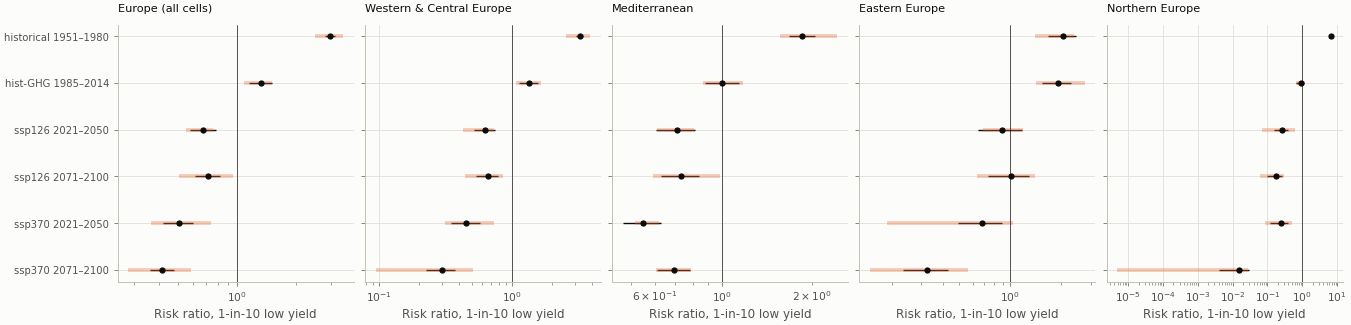

In [3]:
regions = ["Europe", "WCE", "MED", "EEU", "NEU"]
tags = [TAG(*s) for s in SCENARIOS if s[0] != "hist-aer"]
fig, axes = plt.subplots(1, 5, figsize=(15.0, 3.6), sharey=True, layout="constrained")
block = summary[summary["event"] == "p10"]
for ax, r in zip(axes, regions):
    sub = block[block["region"] == r].set_index("scenario").loc[tags]
    ref = sub["reference (%)"]
    ax.errorbar(sub["risk ratio"], range(len(tags)), xerr=[sub["risk ratio"] - sub["CI low (%)"] / ref, sub["CI high (%)"] / ref - sub["risk ratio"]], fmt="o", color=PALETTE["primary"], ms=4, lw=1.1)
    ax.hlines(range(len(tags)), sub["RR model min"], sub["RR model max"], color=PALETTE["series_2"], lw=3, alpha=0.35)
    ax.axvline(1, color="k", lw=0.5)
    ax.set_title(sc.REGION_NAMES[r], fontsize=9)
    ax.set_xscale("log")
    ax.set_xlabel("Risk ratio, 1-in-10 low yield")
axes[0].set_yticks(range(len(tags)), tags, fontsize=8)
axes[0].invert_yaxis()
save(fig, "risk_ratio_p10", FIGURES)
plt.show()

## 2. Probability through time

The area-mean probability of the 1-in-10 low-yield event, in 21-year running means. The dotted line is the leave-one-year-out reference. Before 1951 three models are available.

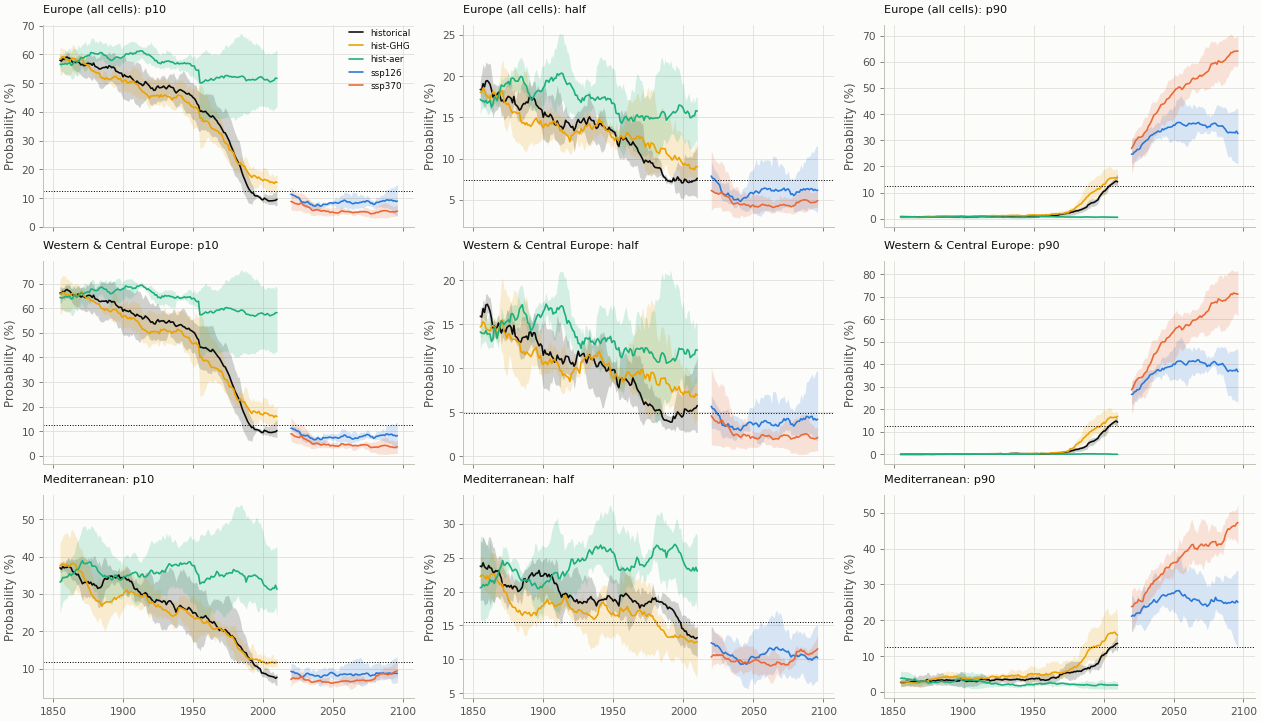

In [4]:
yearly = {key: sc.regional_mean(rk.hits(y, limits[key], rk.EVENT[key]), regions=("Europe", "WCE", "MED")) for key in ("p10", "half", "p90")}
fig, axes = plt.subplots(3, 3, figsize=(14.0, 8.0), sharex=True, layout="constrained")
for r_i, r in enumerate(("Europe", "WCE", "MED")):
    for c, (key, series) in enumerate(yearly.items()):
        ax = axes[r_i, c]
        for e in sc.EXPERIMENTS:
            s = series.sel(region=r, experiment=e).rolling(year=21, center=True, min_periods=15).mean() * 100
            ax.fill_between(s.year, s.min("model"), s.max("model"), color=EXP_COLOURS[e], alpha=0.18, lw=0)
            ax.plot(s.year, s.mean("model"), color=EXP_COLOURS[e], lw=1.3, label=e)
        ax.axhline(100 * float(sc.regional_mean(reference[key]).sel(region=r).mean()), color="k", ls=":", lw=0.8)
        ax.set_title(f"{sc.REGION_NAMES[r]}: {key}", fontsize=9)
        ax.set_ylabel("Probability (%)")
axes[0, 0].legend(frameon=False, fontsize=7)
save(fig, "probability_through_time", FIGURES)
plt.show()

## 3. Where the probability changes

Change in probability (percentage points) against the leave-one-year-out reference. Each model's probability rests on 30 seasons in a cell, so the map shows the mean of four models (120 seasons). Hatching marks cells where fewer than 3 models agree on the sign.

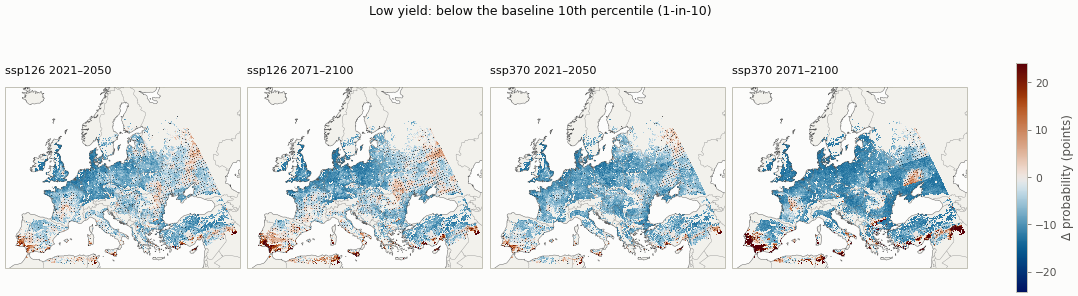

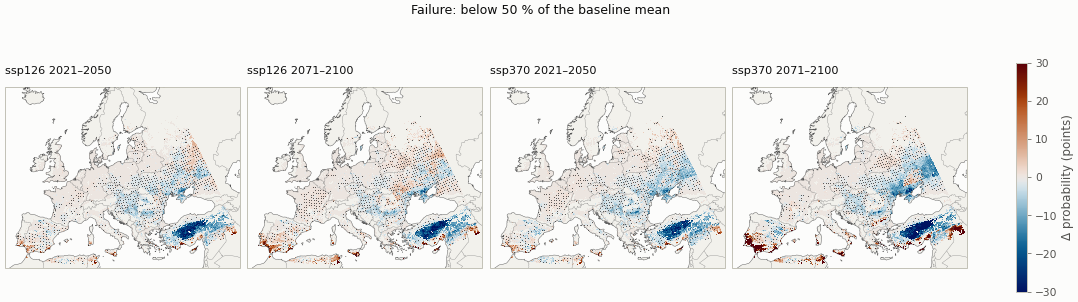

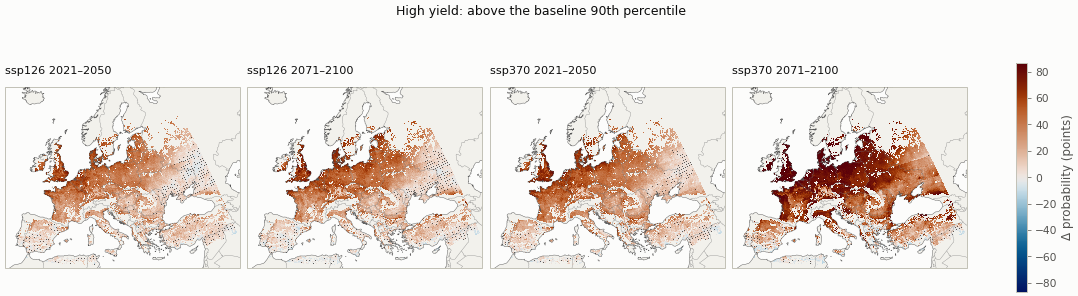

In [5]:
for key in ("p10", "half", "p90"):
    event = rk.EVENT[key]
    delta = {(e, s): 100.0 * (rk.probability(y.sel(experiment=e), limits[key], event, s) - reference[key]) for e, s in FUTURE}
    limit = float(np.nanquantile(np.abs(np.stack([d.mean("model").values for d in delta.values()])), 0.99)) or 1.0
    fig, axes = sc.map_axes(1, 4, 3.0, 3.2)
    for ax, ((e, s), d) in zip(axes[0], delta.items()):
        mesh = sc.draw_map(ax, d.mean("model").values, title=TAG(e, s), hatch=~sc.agreement(d).values, cmap=DIVERGING_CMAP, vmin=-limit, vmax=limit)
    fig.colorbar(mesh, ax=axes, shrink=0.75, label="Δ probability (points)")
    fig.suptitle(event.label, fontsize=10)
    save(fig, f"probability_change_{key}", FIGURES)
    plt.show()

## 4. Is it the mean or the variability?

For the far period, baseline seasons are rescaled by the cell's ratio of future to baseline mean. This keeps the coefficient of variation fixed. The probability of the rescaled seasons is the **mean-only** change; the remainder is the change in **variability and shape**.

part               total  mean shift  variability
experiment region                                
ssp126     EEU       0.1        -2.0          2.1
           EU23     -5.7        -7.1          1.4
           Europe   -3.5        -5.0          1.4
           MED      -3.1        -3.7          0.5
           NEU     -10.3       -11.4          1.1
           WCE      -4.3        -5.9          1.6
ssp370     EEU      -8.5        -8.3         -0.2
           EU23     -8.6        -8.8          0.2
           Europe   -7.2        -7.7          0.5
           MED      -3.7        -4.1          0.5
           NEU     -12.3       -12.4          0.0
           WCE      -8.8        -9.3          0.5

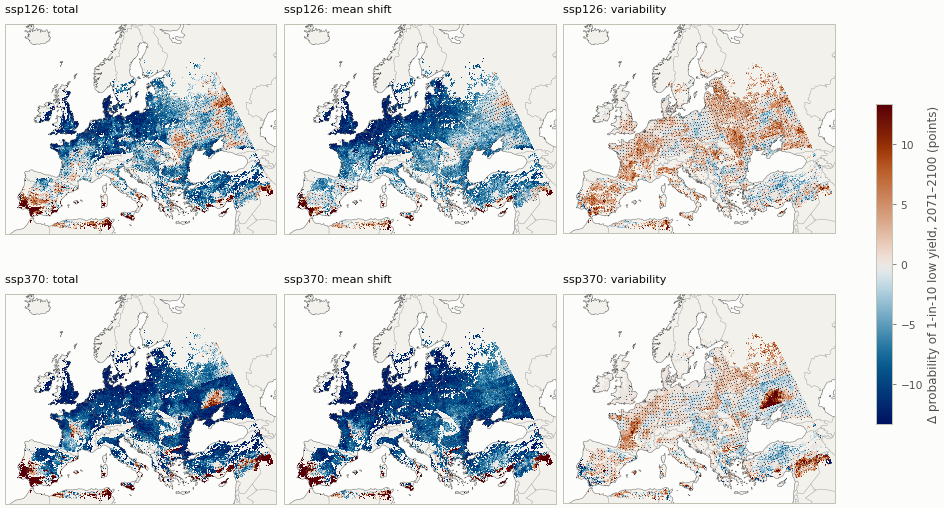

In [6]:
event = rk.EVENT["p10"]
frames, fields = [], {}
for e in sc.FUTURE:
    total = rk.probability(y.sel(experiment=e), limits["p10"], event, sc.FAR) - reference["p10"]
    mean_only = rk.scaled_baseline_probability(y, limits["p10"], event, e, sc.FAR) - reference["p10"]
    variability = total - mean_only
    fields[e] = {"total": total, "mean shift": mean_only, "variability": variability}
    reg = {n: sc.regional_mean(v) * 100 for n, v in fields[e].items()}
    for n, v in reg.items():
        frames.append(v.to_series().rename("points").reset_index().assign(part=n, experiment=e))
parts = pd.concat(frames, ignore_index=True)
parts.to_csv(TABLES / "mean_vs_variability.csv", index=False)
display(parts.groupby(["experiment", "region", "part"])["points"].mean().unstack("part")[["total", "mean shift", "variability"]].round(1))
limit = float(np.nanquantile(np.abs(np.stack([v.mean("model").values for f in fields.values() for v in f.values()])), 0.98)) * 100
fig, axes = sc.map_axes(2, 3, 3.5, 2.75)
for r, (e, f) in enumerate(fields.items()):
    for c, (n, v) in enumerate(f.items()):
        mesh = sc.draw_map(axes[r, c], 100 * v.mean("model").values, title=f"{e}: {n}", hatch=~sc.agreement(v).values, cmap=DIVERGING_CMAP, vmin=-limit, vmax=limit)
fig.colorbar(mesh, ax=axes, shrink=0.6, label=f"Δ probability of 1-in-10 low yield, {SPAN(sc.FAR)} (points)")
save(fig, "mean_vs_variability", FIGURES)
plt.show()

Interannual coefficient of variation (linearly detrended within each window): baseline, then its change.

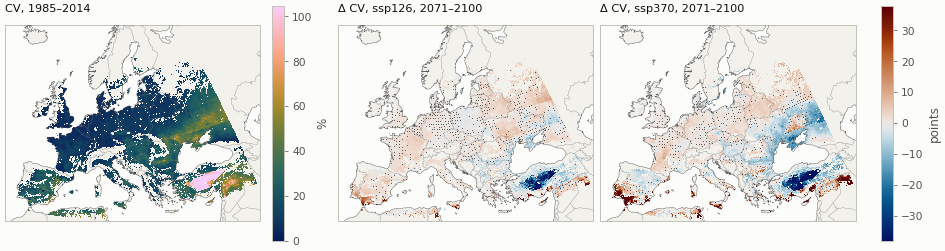

,ssp126,ssp370
Europe (all cells),"-0.3 [-3.0, +1.8]","-2.4 [-4.1, -0.7]"
EU-23 (CyBench countries),"+0.3 [-1.9, +1.4]","-0.2 [-1.3, +1.3]"
Northern Europe,"+0.5 [-0.6, +1.4]","-0.3 [-1.6, +1.1]"
Western & Central Europe,"+0.7 [-2.1, +1.8]","-2.1 [-4.4, -0.6]"
Eastern Europe,"+1.6 [-3.1, +4.2]","-6.1 [-10.3, -2.4]"
Mediterranean,"-5.3 [-7.1, -0.3]","-5.7 [-7.6, -4.0]"


In [7]:
cv_base = rk.coefficient_of_variation(y.sel(experiment="historical"), sc.BASELINE)
cv_change = {e: rk.coefficient_of_variation(y.sel(experiment=e), sc.FAR) - cv_base for e in sc.FUTURE}
fig, axes = sc.map_axes(1, 3, 3.5, 3.6)
fig.colorbar(sc.draw_map(axes[0, 0], cv_base.mean("model").values, cmap=SEQUENTIAL_CMAP, vmin=0, vmax=float(cv_base.mean("model").quantile(0.98)), title=f"CV, {SPAN(sc.BASELINE)}"), ax=axes[0, 0], shrink=0.65, label="%")
scale = sc.diverging(xr.concat([v.mean("model") for v in cv_change.values()], "k"))
for ax, (e, d) in zip(axes[0, 1:], cv_change.items()):
    mesh = sc.draw_map(ax, d.mean("model").values, title=f"Δ CV, {e}, {SPAN(sc.FAR)}", hatch=~sc.agreement(d).values, **scale)
fig.colorbar(mesh, ax=axes[0, 1:], shrink=0.65, label="points")
save(fig, "cv_change", FIGURES)
plt.show()
display(sc.regional_table({e: d for e, d in cv_change.items()}, 1).T)

## 5. Synchronous shortfalls

A 1-in-10 season in one cell can be offset elsewhere; many at once cannot. The share of Europe's cropland below its own 1-in-10 level per season, as the probability that at least x % of cropland is affected in one season. The baseline uses leave-one-year-out thresholds, like the reference in §1.

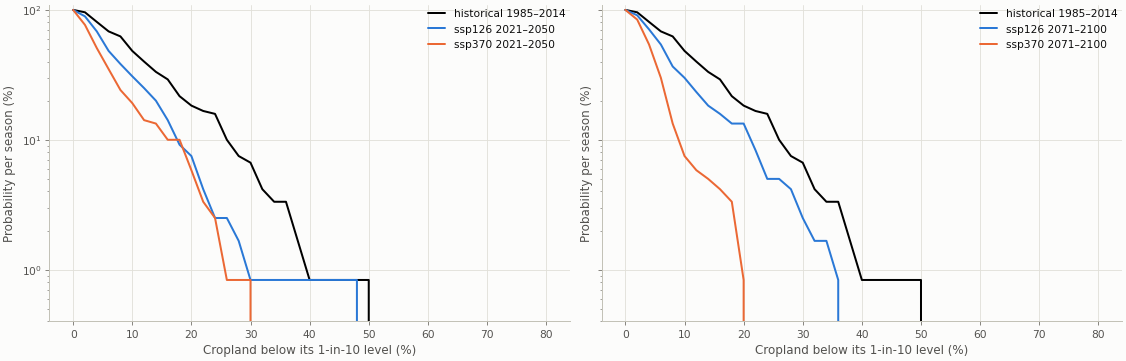

,scenario,P(≥20 %) (%),P(≥30 %) (%),P(≥50 %) (%)
0,historical 1985–2014,18.3,6.7,0.8
1,ssp126 2021–2050,7.5,0.8,0.0
2,ssp370 2021–2050,5.8,0.8,0.0
3,ssp126 2071–2100,13.3,2.5,0.0
4,ssp370 2071–2100,0.8,0.0,0.0


In [8]:
area = sc.regional_mean(rk.hits(y, limits["p10"], rk.EVENT["p10"]), regions=("Europe",)).sel(region="Europe") * 100
levels = np.arange(0, 81, 2)
baseline_area = 100 * sc.regional_mean(rk.loo_hits(y, rk.EVENT["p10"]), regions=("Europe",)).sel(region="Europe").values.ravel()
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0), sharey=True, layout="constrained")
rows = []
for ax, s in zip(axes, (sc.NEAR, sc.FAR)):
    base = baseline_area
    ax.plot(levels, [100 * (base >= x).mean() for x in levels], "k", lw=1.6, label=f"historical {SPAN(sc.BASELINE)}")
    for e in sc.FUTURE:
        vals = sc.period(area.sel(experiment=e), s).values.ravel()
        ax.plot(levels, [100 * (vals >= x).mean() for x in levels], color=EXP_COLOURS[e], lw=1.6, label=f"{e} {SPAN(s)}")
        rows.append({"scenario": TAG(e, s), **{f"P(≥{x} %) (%)": 100 * (vals >= x).mean() for x in (20, 30, 50)}})
    ax.set(yscale="log", xlabel="Cropland below its 1-in-10 level (%)", ylabel="Probability per season (%)", ylim=(0.4, 110))
    ax.legend(frameon=False)
rows.insert(0, {"scenario": f"historical {SPAN(sc.BASELINE)}", **{f"P(≥{x} %) (%)": 100 * (base >= x).mean() for x in (20, 30, 50)}})
synchronous = pd.DataFrame(rows)
synchronous.to_csv(TABLES / "synchronous_shortfall.csv", index=False)
save(fig, "synchronous", FIGURES)
plt.show()
display(synchronous.round(1))

## 6. Continental return levels

Europe's mean yield anomaly against each model's baseline mean. Curves pool all four models' seasons in each period (120 seasons, so about the 1-in-40 level is the limit of what the data support). Plotting position is Weibull, `rank / (n + 1)`.

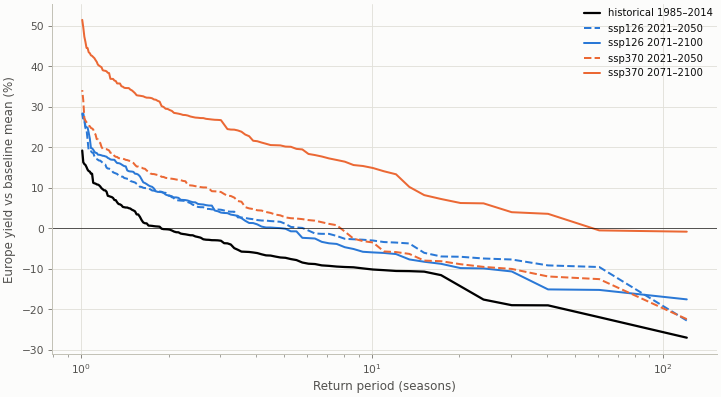

,1-in-5,1-in-10,1-in-20
scenario,,,
historical 1985–2014,-7.3,-10.2,-14.2
ssp126 2021–2050,1.2,-3.0,-7.0
ssp126 2071–2100,-0.1,-5.9,-9.8
ssp370 2021–2050,2.8,-3.5,-8.8
ssp370 2071–2100,20.2,14.9,6.3


In [9]:
series = sc.regional_mean(y, regions=("Europe",)).sel(region="Europe")
anom = 100.0 * (series / sc.clim(series.sel(experiment="historical"), sc.BASELINE) - 1.0)
def return_curve(values):
    v = np.sort(values[np.isfinite(values)])
    return (len(v) + 1) / np.arange(1, len(v) + 1), v
fig, ax = plt.subplots(figsize=(8.0, 4.4), layout="constrained")
rt, lv = return_curve(sc.period(anom.sel(experiment="historical"), sc.BASELINE).values.ravel())
ax.plot(rt, lv, "k", lw=1.8, label=f"historical {SPAN(sc.BASELINE)}")
rows = [{"scenario": f"historical {SPAN(sc.BASELINE)}", **{f"1-in-{t}": float(np.interp(t, rt[::-1], lv[::-1])) for t in (5, 10, 20)}}]
for e, s in FUTURE:
    rt, lv = return_curve(sc.period(anom.sel(experiment=e), s).values.ravel())
    ax.plot(rt, lv, color=EXP_COLOURS[e], lw=1.6, ls="--" if s == sc.NEAR else "-", label=TAG(e, s))
    rows.append({"scenario": TAG(e, s), **{f"1-in-{t}": float(np.interp(t, rt[::-1], lv[::-1])) for t in (5, 10, 20)}})
ax.set(xscale="log", xlabel="Return period (seasons)", ylabel="Europe yield vs baseline mean (%)")
ax.axhline(0, color="k", lw=0.5)
ax.legend(frameon=False, fontsize=8)
save(fig, "return_levels", FIGURES)
plt.show()
levels_table = pd.DataFrame(rows).set_index("scenario")
levels_table.to_csv(TABLES / "return_levels.csv")
display(levels_table.round(1))

## 7. Complete crop failure

The share of cropland area-seasons with zero yield, or not reaching maturity (`final_dvs` < 2). These are model outcomes with fixed sowing dates and a fixed cultivar, so they include a phenology mismatch that a real sowing or cultivar choice would avoid.

In [10]:
dvs = sc.cube("final_dvs")
periods = [("historical", sc.EARLY), ("historical", sc.BASELINE), *FUTURE]
rows = []
for e, s in periods:
    z = sc.regional_mean((sc.period(y.sel(experiment=e), s) == 0).astype(np.float32).where(sc.period(y.sel(experiment=e), s).notnull())).mean("year") * 100
    d = sc.regional_mean((sc.period(dvs.sel(experiment=e), s) < 1.99).astype(np.float32).where(sc.period(dvs.sel(experiment=e), s).notnull())).mean("year") * 100
    rows.append({"scenario": TAG(e, s), **{f"zero yield: {r}": float(z.sel(region=r).mean()) for r in regions}, **{f"not mature: {r}": float(d.sel(region=r).mean()) for r in regions}})
failure = pd.DataFrame(rows).set_index("scenario")
failure.to_csv(TABLES / "complete_failure.csv")
display(failure.round(2).T)

scenario,historical 1951–1980,historical 1985–2014,ssp126 2021–2050,ssp126 2071–2100,ssp370 2021–2050,ssp370 2071–2100
zero yield: Europe,0.54,0.54,0.26,0.28,0.31,0.43
zero yield: WCE,0.00,0.00,0.00,0.00,0.00,0.00
zero yield: MED,2.78,2.77,1.32,1.40,1.61,1.87
zero yield: EEU,0.00,0.00,0.00,0.00,0.00,0.00
zero yield: NEU,0.00,0.00,0.00,0.00,0.00,0.00
not mature: Europe,0.04,0.05,0.07,0.08,0.08,0.42
not mature: WCE,0.00,0.00,0.00,0.00,0.00,0.00
not mature: MED,0.21,0.24,0.31,0.37,0.32,1.19
not mature: EEU,0.00,0.00,0.00,0.00,0.00,0.00
not mature: NEU,0.01,0.00,0.00,0.00,0.00,0.00


## 8. Per country

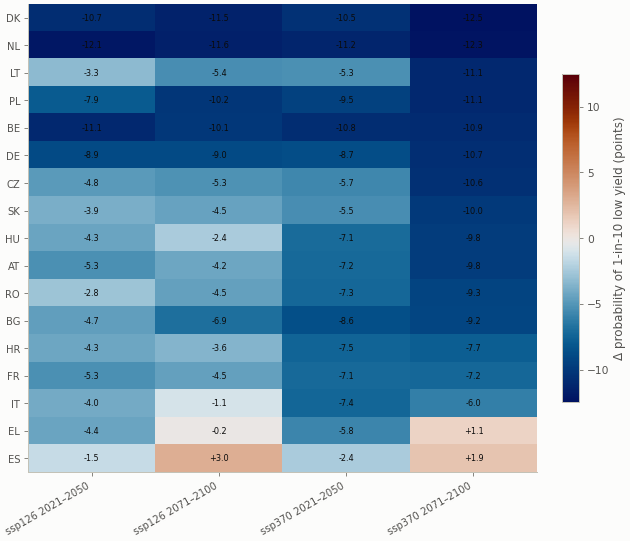

In [11]:
rows = {}
for e, s in FUTURE:
    p = sc.country_series(rk.probability(y.sel(experiment=e), limits["p10"], rk.EVENT["p10"], s))
    ref = sc.country_series(reference["p10"])
    rows[TAG(e, s)] = (100 * (p - ref)).mean("model").to_series()
country = pd.DataFrame(rows).sort_values(TAG("ssp370", sc.FAR))
country.to_csv(TABLES / "country_probability_change.csv")
fig, ax = plt.subplots(figsize=(7.0, 6.0), layout="constrained")
limit = float(np.abs(country.to_numpy()).max())
im = ax.imshow(country.to_numpy(), cmap=DIVERGING_CMAP, vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(country.shape[1]), country.columns, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(country)), country.index, fontsize=8)
ax.grid(False)
for (i, j), v in np.ndenumerate(country.to_numpy()):
    ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=6.5)
fig.colorbar(im, ax=ax, shrink=0.7, label="Δ probability of 1-in-10 low yield (points)")
save(fig, "country_probability", FIGURES)
plt.show()

## 9. Sensitivity: heat-sterility-adjusted yield

`yield_t_ha` leaves out heat sterility, so a change in risk from heat around flowering would not reach it. The tables repeat §1 on `adjusted_yield_t_ha`, using its own thresholds and reference.

In [12]:
adjusted = sc.cube("adjusted_yield_t_ha")
event = rk.EVENT["p10"]
alt = summarise(event, adjusted, rk.threshold(adjusted, event), rk.loo_probability(adjusted, event))
alt.to_csv(TABLES / "event_probability_adjusted.csv", index=False)
compare = (summary[summary["event"] == "p10"].set_index(["scenario", "region"])[["risk ratio"]].rename(columns={"risk ratio": "yield_t_ha"})
           .join(alt.set_index(["scenario", "region"])["risk ratio"].rename("adjusted_yield_t_ha")))
compare["difference"] = compare["adjusted_yield_t_ha"] - compare["yield_t_ha"]
display(compare.loc[[TAG(*s) for s in FUTURE]].unstack("region")["difference"][regions].round(3))
print("Risk ratio, adjusted yield:")
display(compare.loc[[TAG(*s) for s in FUTURE]].unstack("region")["adjusted_yield_t_ha"][regions].round(2))

region,Europe,WCE,MED,EEU,NEU
scenario,,,,,
ssp126 2021–2050,0.047,0.042,0.030,0.105,0.004
ssp126 2071–2100,0.049,0.048,0.029,0.086,0.005
ssp370 2021–2050,0.038,0.029,0.024,0.106,0.001
ssp370 2071–2100,0.076,0.066,0.075,0.093,0.003


Risk ratio, adjusted yield:


region,Europe,WCE,MED,EEU,NEU
scenario,,,,,
ssp126 2021–2050,0.72,0.67,0.74,1.00,0.27
ssp126 2071–2100,0.76,0.71,0.76,1.09,0.18
ssp370 2021–2050,0.55,0.48,0.57,0.79,0.24
ssp370 2071–2100,0.49,0.36,0.77,0.42,0.02


## 10. Sensitivity: with the prescribed CO₂ effect on growth removed

Notebook 05 shows that crop parameter `COTB`, which multiplies radiation-use efficiency by a function of CO₂, accounts for nearly all of the mean yield gain. So how much of the falling risk comes from `COTB`? Each season's yield is divided by its `COTB` factor relative to the 1985–2014 mean, and §1 is repeated with its own thresholds.

This is an approximation, not a rerun. It assumes yield scales directly with RUE, and it leaves in CO₂'s reduction of transpiration. `hist-aer` tests the approximation: its climate has no greenhouse warming, so once its low CO₂ is divided out, its risk ratio should be close to or below 1.

Mean yield change without COTB (%), multi-model mean [model range]:


,historical 1951–1980,hist-GHG 1985–2014,hist-aer 1985–2014,ssp126 2021–2050,ssp126 2071–2100,ssp370 2021–2050,ssp370 2071–2100
Europe (all cells),"-2.7 [-4.9, +0.9]","-3.0 [-4.4, -2.0]","-0.4 [-5.7, +3.1]","-0.4 [-2.5, +2.5]","-1.2 [-4.1, +1.2]","+0.2 [-4.1, +3.7]","-5.3 [-9.6, -1.8]"
EU-23 (CyBench countries),"-1.5 [-3.9, +0.8]","-0.3 [-2.3, +1.3]","+0.8 [-3.4, +4.2]","+0.7 [-0.8, +3.1]","-0.3 [-1.6, +1.3]","+0.4 [-1.2, +1.4]","-8.2 [-11.4, -4.8]"
Northern Europe,"-3.1 [-4.0, -2.0]","+0.8 [-0.5, +2.2]","-1.2 [-2.3, -0.2]","+2.5 [+0.6, +3.9]","+2.7 [+1.2, +4.4]","+2.3 [-0.1, +4.1]","-0.2 [-4.0, +3.1]"
Western & Central Europe,"-2.4 [-5.1, +1.3]","-2.8 [-3.7, -2.1]","-0.1 [-6.1, +4.6]","-0.6 [-2.4, +2.7]","-1.3 [-3.8, +0.7]","-0.1 [-4.5, +3.2]","-5.8 [-10.0, -1.2]"
Eastern Europe,"-8.2 [-12.9, +1.1]","-15.5 [-22.1, -11.6]","-4.6 [-9.2, -0.6]","-6.4 [-9.9, -1.4]","-6.7 [-14.2, -0.1]","-3.0 [-16.9, +5.1]","-2.4 [-9.2, +4.3]"
Mediterranean,"+0.2 [-2.1, +2.8]","+2.4 [-0.3, +5.4]","+1.9 [-7.4, +11.4]","+3.5 [+0.1, +7.1]","+1.4 [-2.7, +3.4]","+4.4 [+2.0, +7.8]","-6.2 [-8.2, -4.4]"


Low yield: below the baseline 10th percentile (1-in-10) — risk ratio without COTB


region,Europe,WCE,MED,EEU,NEU
scenario,,,,,
historical 1951–1980,1.27,1.25,1.05,1.46,1.92
hist-GHG 1985–2014,1.34,1.36,1.00,1.91,0.98
hist-aer 1985–2014,1.18,1.14,1.16,1.24,1.51
ssp126 2021–2050,1.03,1.01,1.01,1.14,0.69
ssp126 2071–2100,1.13,1.12,1.08,1.29,0.65
ssp370 2021–2050,0.91,0.89,0.88,0.96,0.68
ssp370 2071–2100,1.81,1.96,1.73,0.88,1.21


Failure: below 50 % of the baseline mean — risk ratio without COTB


region,Europe,WCE,MED,EEU,NEU
scenario,,,,,
historical 1951–1980,1.16,1.12,1.01,1.61,2.54
hist-GHG 1985–2014,1.31,1.50,0.83,2.11,6.12
hist-aer 1985–2014,1.22,1.24,1.13,1.34,4.12
ssp126 2021–2050,0.88,0.86,0.74,1.22,5.11
ssp126 2071–2100,1.01,1.06,0.78,1.34,1.02
ssp370 2021–2050,0.81,0.77,0.72,0.97,3.87
ssp370 2071–2100,0.98,0.81,0.97,0.83,0.31


High yield: above the baseline 90th percentile — risk ratio without COTB


region,Europe,WCE,MED,EEU,NEU
scenario,,,,,
historical 1951–1980,0.73,0.66,1.08,0.61,0.42
hist-GHG 1985–2014,1.14,1.24,1.18,0.49,1.58
hist-aer 1985–2014,1.23,1.27,1.36,0.93,1.09
ssp126 2021–2050,1.05,1.04,1.11,0.60,2.27
ssp126 2071–2100,1.07,1.11,1.05,0.59,2.23
ssp370 2021–2050,0.98,0.94,1.13,0.65,2.08
ssp370 2071–2100,0.55,0.50,0.70,0.43,0.95


,reference (%),probability (%),CI low (%),CI high (%),risk ratio,RR model min,RR model max
scenario,,,,,,,
historical 1951–1980,12.43,15.80,14.16,17.40,1.27,0.86,1.54
hist-GHG 1985–2014,12.43,16.65,14.49,18.87,1.34,1.08,1.50
hist-aer 1985–2014,12.43,14.62,12.89,16.38,1.18,0.89,1.69
ssp126 2021–2050,12.43,12.75,11.29,14.30,1.03,0.79,1.12
ssp126 2071–2100,12.43,14.06,12.34,15.76,1.13,0.87,1.34
ssp370 2021–2050,12.43,11.35,9.99,12.79,0.91,0.77,1.16
ssp370 2071–2100,12.43,22.45,20.82,24.28,1.81,1.52,2.30


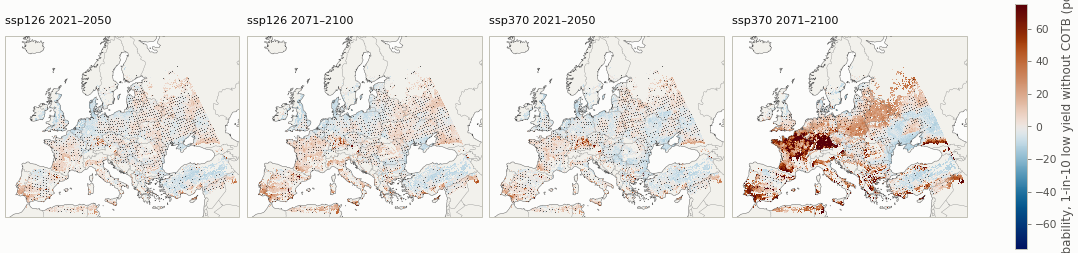

,scenario,"cropland, risk rising (robust, %)","cropland, risk falling (robust, %)"
0,ssp126 2021–2050,16.299999,26.799999
1,ssp126 2071–2100,25.500000,24.000000
2,ssp370 2021–2050,11.000000,41.599998
3,ssp370 2071–2100,36.799999,31.200001


In [13]:
import explain as xp

ppm, rue = xp.cotb_table()
co2 = sc.co2_series()
factor = xr.DataArray(np.stack([np.interp(co2[e].to_numpy(), ppm, rue) for e in sc.EXPERIMENTS]), dims=("experiment", "year"),
                      coords={"experiment": list(sc.EXPERIMENTS), "year": co2.index.to_numpy()})
factor = factor / float(factor.sel(experiment="historical").sel(year=slice(*sc.BASELINE)).mean())
rescaled = (y / factor.astype(np.float32)).rename("yield_without_cotb")
mean_change = sc.regional_table({TAG(e, s): sc.regional_relative_change(rescaled, e, s) for e, s in SCENARIOS}, 1)
mean_change.to_csv(TABLES / "mean_change_without_cotb.csv")
print("Mean yield change without COTB (%), multi-model mean [model range]:")
display(mean_change.T)
without = pd.concat([summarise(e, rescaled, rk.threshold(rescaled, e), rk.loo_probability(rescaled, e)) for e in (rk.EVENT["p10"], rk.EVENT["half"], rk.EVENT["p90"])], ignore_index=True)
without.to_csv(TABLES / "event_probability_without_cotb.csv", index=False)
for key in ("p10", "half", "p90"):
    print(rk.EVENT[key].label, "— risk ratio without COTB")
    display(without[(without["event"] == key) & without["region"].isin(regions)].pivot(index="scenario", columns="region", values="risk ratio").reindex([TAG(*s) for s in SCENARIOS])[regions].round(2))
display(without[(without["event"] == "p10") & (without["region"] == "Europe")].drop(columns=["event", "region"]).set_index("scenario").round(2))

limit_r, ref_r = rk.threshold(rescaled, rk.EVENT["p10"]), rk.loo_probability(rescaled, rk.EVENT["p10"])
delta = {(e, s): 100.0 * (rk.probability(rescaled.sel(experiment=e), limit_r, rk.EVENT["p10"], s) - ref_r) for e, s in FUTURE}
limit = float(np.nanquantile(np.abs(np.stack([d.mean("model").values for d in delta.values()])), 0.99)) or 1.0
fig, axes = sc.map_axes(1, 4, 3.0, 3.2)
for ax, ((e, s), d) in zip(axes[0], delta.items()):
    mesh = sc.draw_map(ax, d.mean("model").values, title=TAG(e, s), hatch=~sc.agreement(d).values, cmap=DIVERGING_CMAP, vmin=-limit, vmax=limit)
fig.colorbar(mesh, ax=axes, shrink=0.75, label="Δ probability, 1-in-10 low yield without COTB (points)")
save(fig, "probability_change_without_cotb", FIGURES)
plt.show()
w = cells.weight / cells.weight.sum()
display(pd.DataFrame([{"scenario": TAG(e, s), "cropland, risk rising (robust, %)": 100 * w[(sc.agreement(d).values) & (d.mean("model").values > 0)].sum(),
                       "cropland, risk falling (robust, %)": 100 * w[(sc.agreement(d).values) & (d.mean("model").values < 0)].sum()} for (e, s), d in delta.items()]).round(1))